# Public Transportation Usage – Exploratory Data Analysis (EDA)

## Project Overview

This project explores public transportation usage patterns across multiple international cities using a synthetic transportation dataset.

The objective is to identify passenger demand patterns, analyze transportation performance, investigate service delays, and discover insights that can support better operational and business decisions.

## Objectives

- Analyze passenger demand across cities and transport types.
- Understand passenger boarding and alighting patterns.
- Evaluate transportation service reliability.
- Investigate occupancy rates and vehicle capacity.
- Explore temporal trends in transportation usage.
- Identify patterns and potential operational inefficiencies.

## Dataset Information

- **Dataset:** Public Transportation Usage Dataset
- **Records:** 500,000
- **Columns:** 33 (including two data-quality flags)
- **Cities:** London, Paris, Berlin, Tokyo, New York
- **Data Period:** January 2020 – December 2020
- **Data Type:** Synthetic dataset

## Tools & Technologies

Python, Pandas, NumPy, Matplotlib and Seaborn.

## Analysis Workflow

Data Loading → Dataset Overview → Univariate Analysis → Bivariate Analysis → Multivariate Analysis → Time-Series Analysis → Business Insights.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization style
sns.set_theme(style="whitegrid", palette="viridis")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r"C:\Users\admin\Documents\Projects\Public_Transportation_Performance_Intelligence\Data\processed\public_transportation_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (500000, 33)


In [3]:
# First 5 records
display(df.head())

# Random 5 records
display(df.sample(5, random_state=42))

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column information
df.info()

,trip_id,timestamp,route_id,city,route_type,origin_station,dest_station,boarding_count,alighting_count,passenger_count,occupancy_rate,delay_minutes,actual_travel_min,scheduled_travel_min,service_status,cancellation_flag,fare_type,weather_condition,temperature_c,route_length_km,headway_min,vehicle_capacity,operates_night,is_electric,is_peak_hour,is_weekend,is_holiday,is_school_hours,is_night_service,anomaly_flag,anomaly_type,boarding_passenger_mismatch,status_delay_mismatch
0,TRIP_RT_LON_000_0000000,2020-01-01 00:00:00,RT_LON_000,London,rail,STN_LON_0066,STN_LON_0009,0,0,0,0.00,0,100.40,97.40,on_time,0,tourist_pass,clear,3.72,48.70,59,600,1,1,0,0,1,0,1,0,none,0,0
1,TRIP_RT_LON_000_0000001,2020-01-01 01:00:00,RT_LON_000,London,rail,STN_LON_0066,STN_LON_0009,0,0,0,0.00,0,96.60,97.40,on_time,0,concession,clear,6.18,48.70,59,600,1,1,0,0,1,0,1,0,none,0,0
2,TRIP_RT_LON_000_0000002,2020-01-01 02:00:00,RT_LON_000,London,rail,STN_LON_0066,STN_LON_0009,0,0,0,0.00,0,92.90,97.40,on_time,0,group,clear,4.53,48.70,59,600,1,1,0,0,1,0,1,0,none,0,0
3,TRIP_RT_LON_000_0000003,2020-01-01 03:00:00,RT_LON_000,London,rail,STN_LON_0066,STN_LON_0009,0,0,0,0.00,0,97.90,97.40,major_delay,0,standard,heavy_rain,5.20,48.70,59,600,1,1,0,0,1,0,1,0,none,0,1
4,TRIP_RT_LON_000_0000004,2020-01-01 04:00:00,RT_LON_000,London,rail,STN_LON_0066,STN_LON_0009,0,0,0,0.00,0,95.80,97.40,on_time,0,concession,storm,3.86,48.70,59,600,1,1,0,0,1,0,1,0,none,0,0


,trip_id,timestamp,route_id,city,route_type,origin_station,dest_station,boarding_count,alighting_count,passenger_count,occupancy_rate,delay_minutes,actual_travel_min,scheduled_travel_min,service_status,cancellation_flag,fare_type,weather_condition,temperature_c,route_length_km,headway_min,vehicle_capacity,operates_night,is_electric,is_peak_hour,is_weekend,is_holiday,is_school_hours,is_night_service,anomaly_flag,anomaly_type,boarding_passenger_mismatch,status_delay_mismatch
104241,TRIP_RT_NEW_000_0007881,2020-11-24 09:00:00,RT_NEW_000,New_York,bus,STN_NEW_0136,STN_NEW_0045,3,3,72,0.90,0,74.80,73.80,on_time,0,standard,light_rain,2.38,36.90,14,80,1,1,1,0,0,1,0,0,none,0,0
199676,TRIP_RT_BER_002_0006956,2020-10-16 20:00:00,RT_BER_002,Berlin,rail,STN_BER_0094,STN_BER_0127,0,0,0,0.00,0,24.10,25.40,on_time,0,tourist_pass,snow,6.29,12.70,48,600,0,1,0,0,0,0,0,0,none,0,0
140199,TRIP_RT_NEW_005_0000039,2020-01-02 15:00:00,RT_NEW_005,New_York,rail,STN_NEW_0172,STN_NEW_0107,2,2,3,0.01,0,93.00,94.20,on_time,0,standard,light_rain,1.64,47.10,17,600,0,0,0,0,0,1,0,0,none,0,0
132814,TRIP_RT_NEW_004_0001414,2020-02-28 22:00:00,RT_NEW_004,New_York,rail,STN_NEW_0097,STN_NEW_0103,0,0,73,0.12,0,23.60,24.60,on_time,0,concession,cloudy,12.85,12.30,52,600,0,0,0,0,0,0,0,0,none,0,0
408697,TRIP_RT_PAR_003_0005737,2020-08-27 01:00:00,RT_PAR_003,Paris,metro,STN_PAR_0085,STN_PAR_0266,0,0,79,0.10,0,80.90,79.40,minor_delay,0,standard,clear,22.69,39.70,6,800,0,0,0,0,0,0,1,0,none,0,1


Rows: 500000
Columns: 33
<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   trip_id                      500000 non-null  str    
 1   timestamp                    500000 non-null  str    
 2   route_id                     500000 non-null  str    
 3   city                         500000 non-null  str    
 4   route_type                   500000 non-null  str    
 5   origin_station               500000 non-null  str    
 6   dest_station                 500000 non-null  str    
 7   boarding_count               500000 non-null  int64  
 8   alighting_count              500000 non-null  int64  
 9   passenger_count              500000 non-null  int64  
 10  occupancy_rate               500000 non-null  float64
 11  delay_minutes                500000 non-null  int64  
 12  actual_travel_min            500000 non-null

In [4]:
# Convert timestamp into datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

# Verify datatype
print("Timestamp datatype:", df["timestamp"].dtype)

# Check invalid timestamps
print("Invalid timestamps:", df["timestamp"].isna().sum())

# Extract date components
df["year"] = df["timestamp"].dt.year
df["month"] = df["timestamp"].dt.month
df["day"] = df["timestamp"].dt.day
df["hour"] = df["timestamp"].dt.hour
df["day_name"] = df["timestamp"].dt.day_name()

print("Timestamp conversion completed!")

Timestamp datatype: datetime64[us]
Invalid timestamps: 0
Timestamp conversion completed!


In [5]:
# Numerical columns summary
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
timestamp,500000,2020-07-01 06:00:20.159999,2020-01-01 00:00:00,2020-03-31 21:00:00,2020-07-01 06:00:00,2020-09-30 15:00:00,2020-12-30 23:00:00,NaN
boarding_count,500000.00,1.37,0.00,0.00,0.00,2.00,54.00,2.52
alighting_count,500000.00,1.32,0.00,0.00,0.00,2.00,22.00,2.37
passenger_count,500000.00,78.92,0.00,0.00,7.00,66.00,800.00,154.15
occupancy_rate,500000.00,0.18,0.00,0.00,0.01,0.29,1.00,0.27
delay_minutes,500000.00,0.65,0.00,0.00,0.00,0.00,86.00,3.15
actual_travel_min,500000.00,68.49,1.90,40.80,72.00,97.00,153.20,32.58
scheduled_travel_min,500000.00,68.17,10.60,41.20,72.20,97.40,119.00,32.42
cancellation_flag,500000.00,0.04,0.00,0.00,0.00,0.00,1.00,0.20
temperature_c,500000.00,14.99,-6.97,8.40,14.97,21.60,37.81,7.68


In [6]:
# Categorical columns summary
categorical_cols = df.select_dtypes(
    include=["object", "str"]
).columns

display(df[categorical_cols].describe().T)

,count,unique,top,freq
trip_id,500000,500000,TRIP_RT_LON_000_0000000,1
route_id,500000,58,RT_LON_000,8760
city,500000,5,Paris,123320
route_type,500000,4,rail,166440
origin_station,500000,58,STN_LON_0066,8760
dest_station,500000,57,STN_PAR_0215,17520
service_status,500000,5,on_time,359926
fare_type,500000,6,standard,225612
weather_condition,500000,7,clear,189759
anomaly_type,500000,4,none,496972


In [7]:
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [
        df[col].nunique() for col in df.columns
    ]
})

display(
    unique_summary.sort_values(
        "Unique_Values",
        ascending=False
    )
)

,Column,Unique_Values
0,trip_id,500000
1,timestamp,8760
18,temperature_c,3874
12,actual_travel_min,1350
10,occupancy_rate,1001
9,passenger_count,801
11,delay_minutes,71
2,route_id,58
5,origin_station,58
6,dest_station,57


In [8]:
df["timestamp"].dtype

dtype('<M8[us]')

In [10]:
categorical_cols = df.select_dtypes(include=["object", "str"]).columns
display(df[categorical_cols].describe().T)

,count,unique,top,freq
trip_id,500000,500000,TRIP_RT_LON_000_0000000,1
route_id,500000,58,RT_LON_000,8760
city,500000,5,Paris,123320
route_type,500000,4,rail,166440
origin_station,500000,58,STN_LON_0066,8760
dest_station,500000,57,STN_PAR_0215,17520
service_status,500000,5,on_time,359926
fare_type,500000,6,standard,225612
weather_condition,500000,7,clear,189759
anomaly_type,500000,4,none,496972


In [11]:
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [df[col].nunique() for col in df.columns]
})

display(unique_summary.sort_values("Unique_Values", ascending=False))

,Column,Unique_Values
0,trip_id,500000
1,timestamp,8760
18,temperature_c,3874
12,actual_travel_min,1350
10,occupancy_rate,1001
9,passenger_count,801
11,delay_minutes,71
2,route_id,58
5,origin_station,58
6,dest_station,57


In [14]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Total Numerical Columns:", len(numeric_cols))
print(numeric_cols)

Total Numerical Columns: 26
['boarding_count', 'alighting_count', 'passenger_count', 'occupancy_rate', 'delay_minutes', 'actual_travel_min', 'scheduled_travel_min', 'cancellation_flag', 'temperature_c', 'route_length_km', 'headway_min', 'vehicle_capacity', 'operates_night', 'is_electric', 'is_peak_hour', 'is_weekend', 'is_holiday', 'is_school_hours', 'is_night_service', 'anomaly_flag', 'boarding_passenger_mismatch', 'status_delay_mismatch', 'year', 'month', 'day', 'hour']


In [15]:
display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
boarding_count,500000.00,1.37,2.52,0.00,0.00,0.00,2.00,54.00
alighting_count,500000.00,1.32,2.37,0.00,0.00,0.00,2.00,22.00
passenger_count,500000.00,78.92,154.15,0.00,0.00,7.00,66.00,800.00
occupancy_rate,500000.00,0.18,0.27,0.00,0.00,0.01,0.29,1.00
delay_minutes,500000.00,0.65,3.15,0.00,0.00,0.00,0.00,86.00
actual_travel_min,500000.00,68.49,32.58,1.90,40.80,72.00,97.00,153.20
scheduled_travel_min,500000.00,68.17,32.42,10.60,41.20,72.20,97.40,119.00
cancellation_flag,500000.00,0.04,0.20,0.00,0.00,0.00,0.00,1.00
temperature_c,500000.00,14.99,7.68,-6.97,8.40,14.97,21.60,37.81
route_length_km,500000.00,34.08,16.21,5.30,20.60,36.10,48.70,59.50


In [16]:
categorical_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()

print("Total Categorical Columns:", len(categorical_cols))
print(categorical_cols)

Total Categorical Columns: 11
['trip_id', 'route_id', 'city', 'route_type', 'origin_station', 'dest_station', 'service_status', 'fare_type', 'weather_condition', 'anomaly_type', 'day_name']


In [18]:
categorical_analysis_cols = [
    "city",
    "route_type",
    "service_status",
    "fare_type",
    "weather_condition",
    "anomaly_type",
    "day_name"
]

for col in categorical_analysis_cols:
    print(f"\n{'='*45}")
    print(f"{col.upper()} DISTRIBUTION")
    print(df[col].value_counts().sort_values(ascending = False))


CITY DISTRIBUTION
city
Paris       123320
Tokyo       113880
London       96360
Berlin       87600
New_York     78840
Name: count, dtype: int64

ROUTE_TYPE DISTRIBUTION
route_type
rail     166440
metro    140160
bus      123320
tram      70080
Name: count, dtype: int64

SERVICE_STATUS DISTRIBUTION
service_status
on_time        359926
minor_delay     75112
major_delay     34876
cancelled       20070
diverted        10016
Name: count, dtype: int64

FARE_TYPE DISTRIBUTION
fare_type
standard        225612
concession       99883
child            59656
tourist_pass     39960
group            39853
monthly_pass     35036
Name: count, dtype: int64

WEATHER_CONDITION DISTRIBUTION
weather_condition
clear         189759
cloudy        140089
light_rain     75192
heavy_rain     34912
fog            24930
snow           20039
storm          15079
Name: count, dtype: int64

ANOMALY_TYPE DISTRIBUTION
anomaly_type
none               496972
demand_spike         1931
service_drop         1012
cascading_

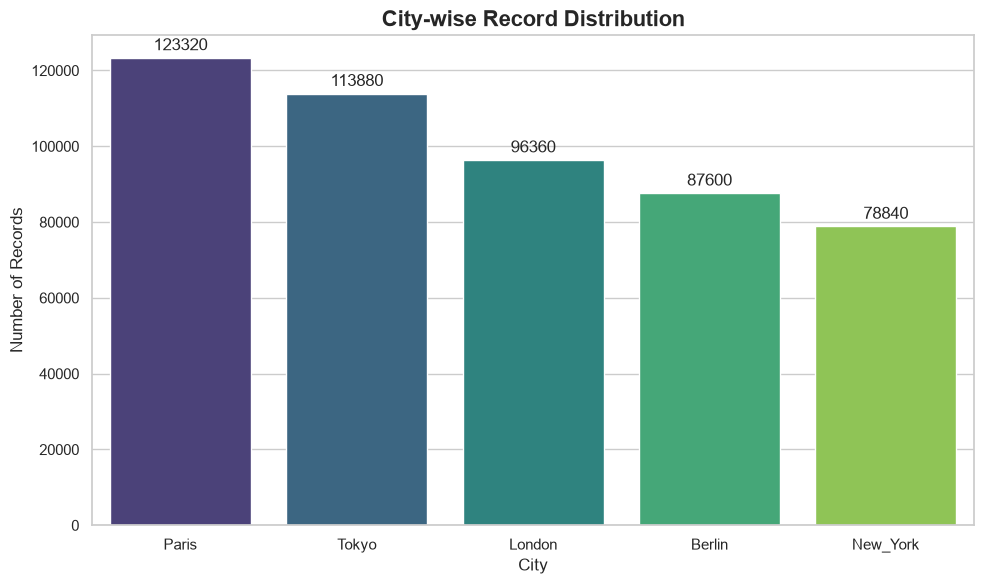

In [20]:
city_counts = df["city"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=city_counts.index,
    y=city_counts.values,
    hue=city_counts.index,
    palette="viridis",
    legend=False
)

plt.title("City-wise Record Distribution", fontsize=16, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

### Key Insights — City-wise Record Distribution

- Paris contributes the highest number of records (123,320), representing approximately 24.66% of the dataset.
- New York has the lowest representation, with 78,840 records (15.77%).
- Paris has 44,480 more records than New York.
- The dataset has an uneven distribution of records across the five cities.

**Business Note:** Record volume does not directly represent passenger demand. Further analysis using passenger_count and boarding_count is required to compare actual transportation usage.

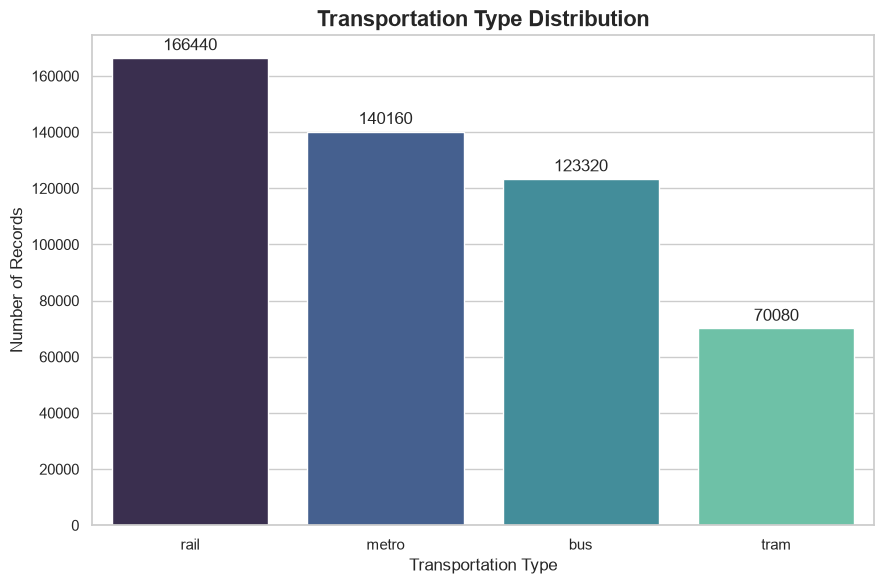

In [23]:
route_counts = df["route_type"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=route_counts.index,
    y=route_counts.values,
    hue=route_counts.index,
    palette="mako",
    legend=False
)

plt.title("Transportation Type Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Transportation Type")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

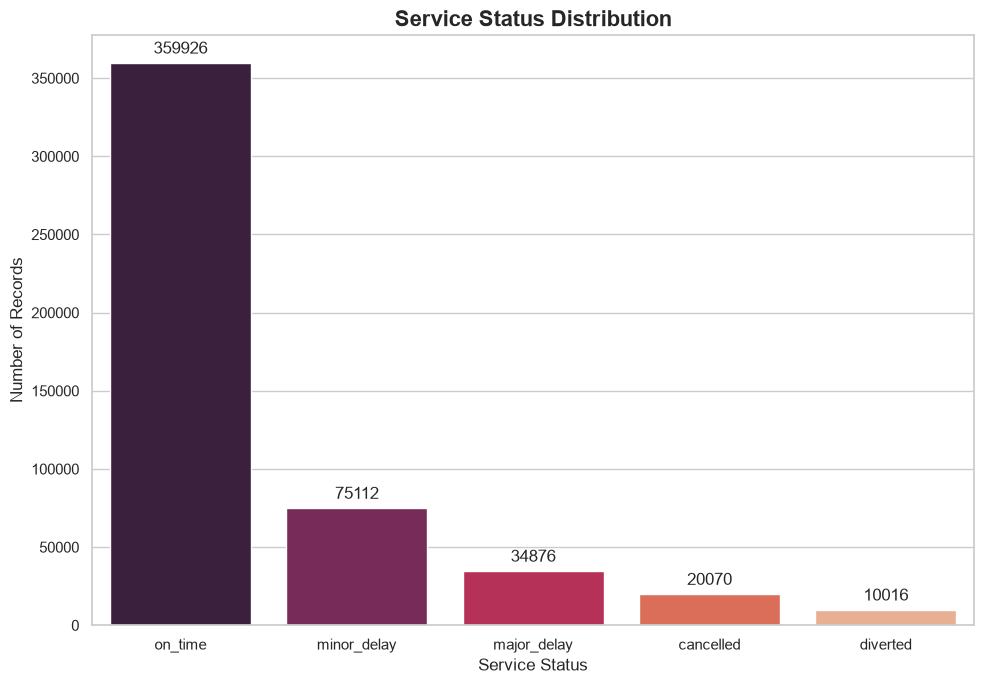

In [29]:
status_counts = df["service_status"].value_counts()

plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    hue=status_counts.index,
    palette="rocket",
    legend=False
)

plt.title(
    "Service Status Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Service Status", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

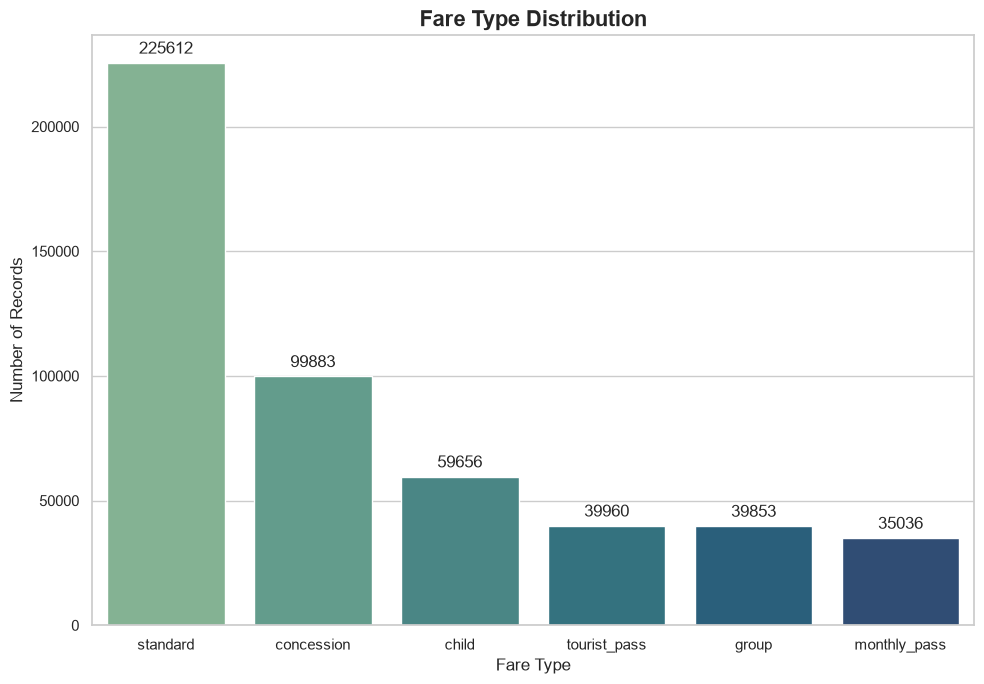

In [32]:
fare_counts = df["fare_type"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=fare_counts.index,
    y=fare_counts.values,
    hue=fare_counts.index,
    palette="crest",
    legend=False
)

plt.title(
    "Fare Type Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Fare Type", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

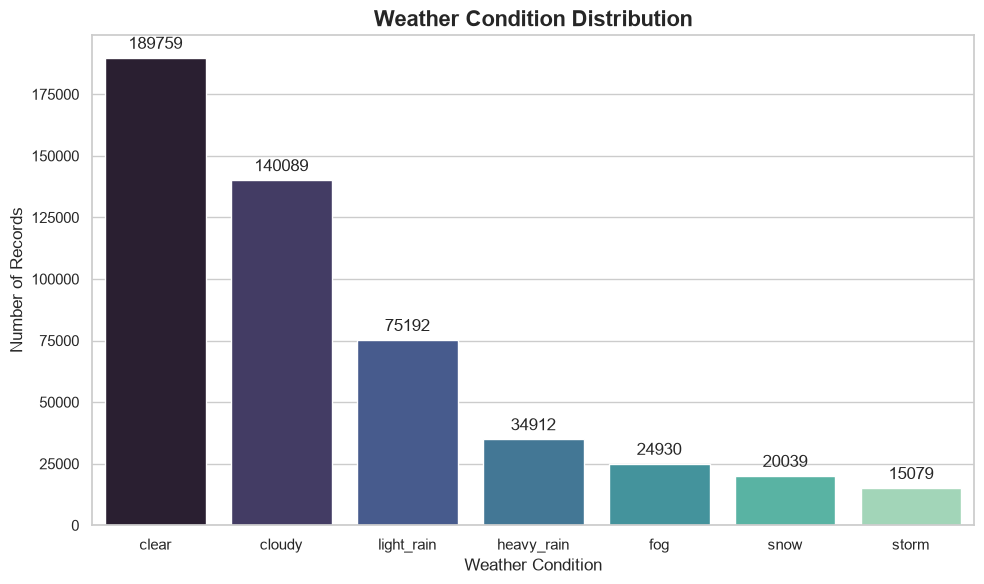

In [34]:
weather_counts = df["weather_condition"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=weather_counts.index,
    y=weather_counts.values,
    hue=weather_counts.index,
    palette="mako",
    legend=False
)

plt.title(
    "Weather Condition Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Weather Condition", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

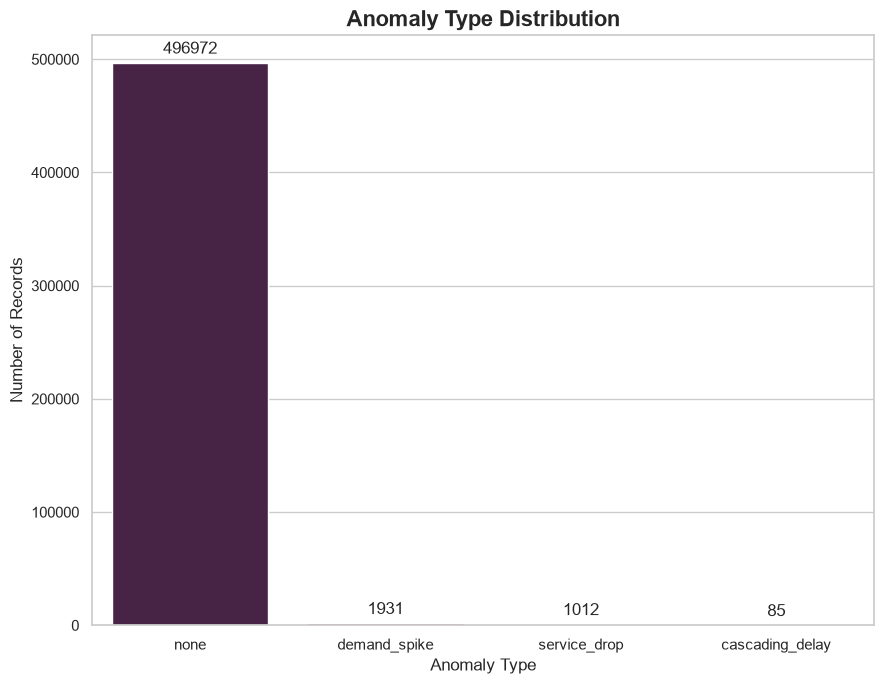

In [37]:
anomaly_counts = df["anomaly_type"].value_counts()

plt.figure(figsize=(9, 7))

ax = sns.barplot(
    x=anomaly_counts.index,
    y=anomaly_counts.values,
    hue=anomaly_counts.index,
    palette="rocket",
    legend=False
)

plt.title(
    "Anomaly Type Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Anomaly Type", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

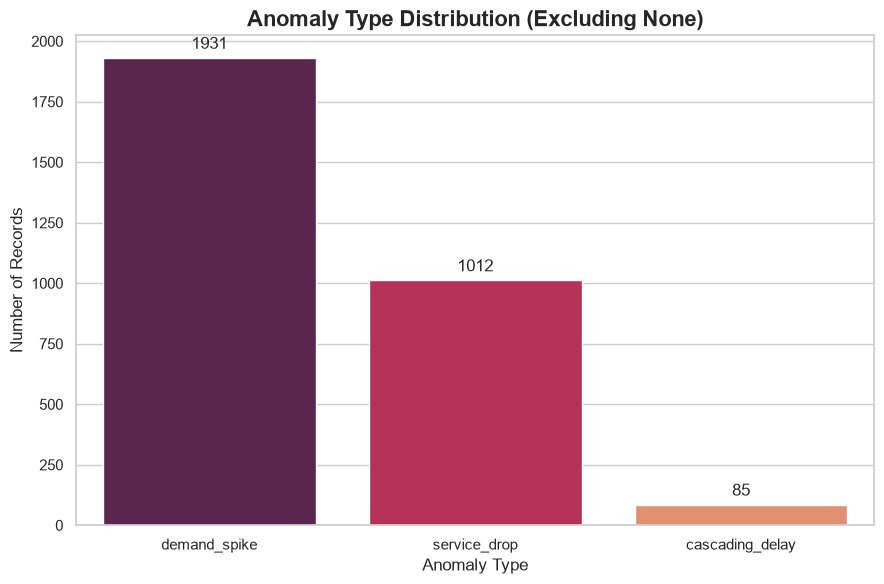

In [39]:
anomaly_counts = (
    df.loc[df["anomaly_type"] != "none", "anomaly_type"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=anomaly_counts.index,
    y=anomaly_counts.values,
    hue=anomaly_counts.index,
    palette="rocket",
    legend=False
)

plt.title(
    "Anomaly Type Distribution (Excluding None)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Anomaly Type", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

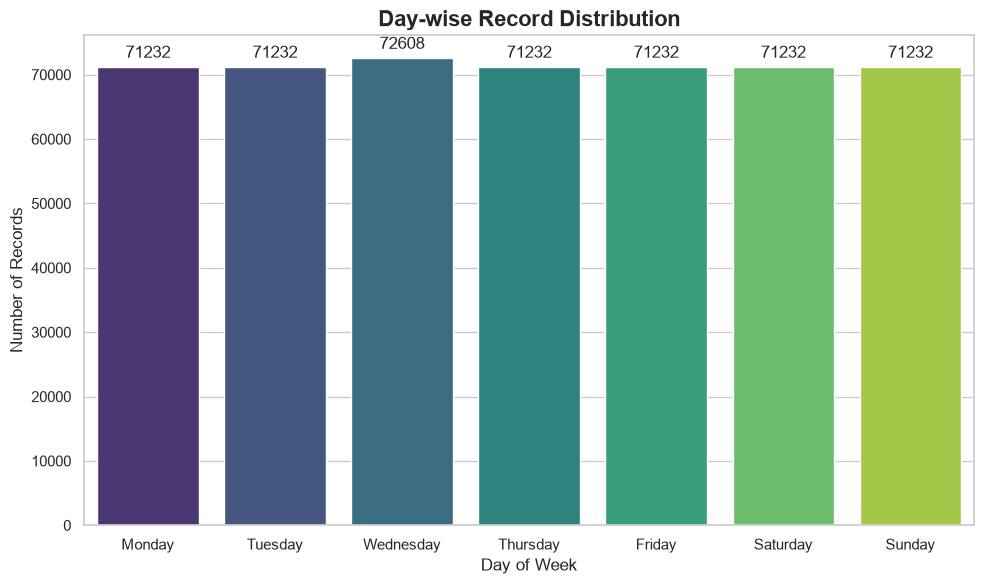

In [43]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_counts = (
    df["day_name"]
    .value_counts()
    .reindex(day_order)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=day_counts.index,
    y=day_counts.values,
    hue=day_counts.index,
    palette="viridis",
    legend=False
)

plt.title(
    "Day-wise Record Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Day of Week", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

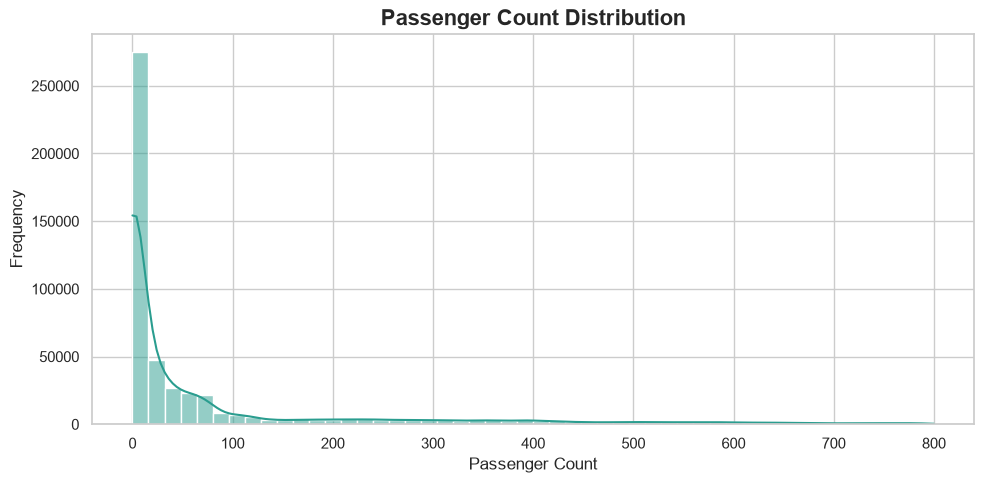

In [44]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="passenger_count",
    bins=50,
    kde=True,
    color="#2A9D8F"
)

plt.title(
    "Passenger Count Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Passenger Count", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

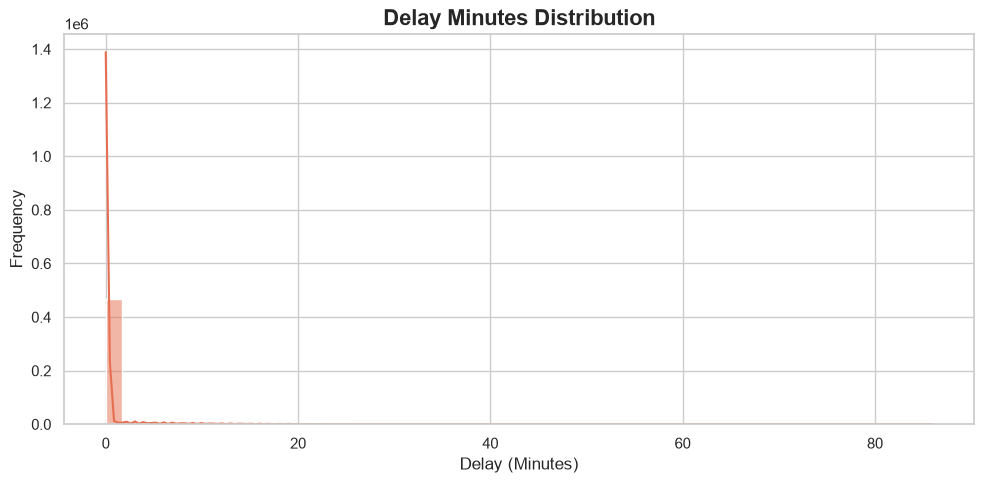

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="delay_minutes",
    bins=50,
    kde=True,
    color="#E76F51"
)

plt.title(
    "Delay Minutes Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Delay (Minutes)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

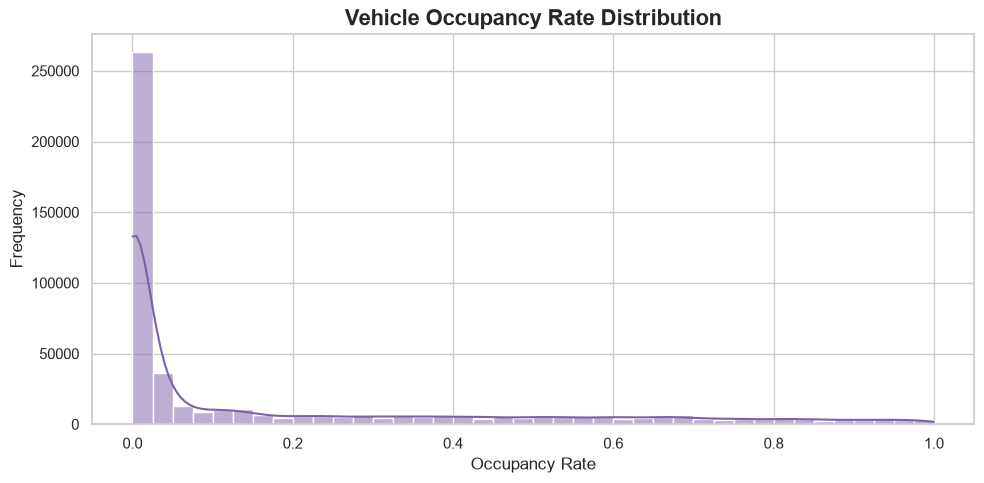

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="occupancy_rate",
    bins=40,
    kde=True,
    color="#7B61A8"
)

plt.title(
    "Vehicle Occupancy Rate Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Occupancy Rate", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

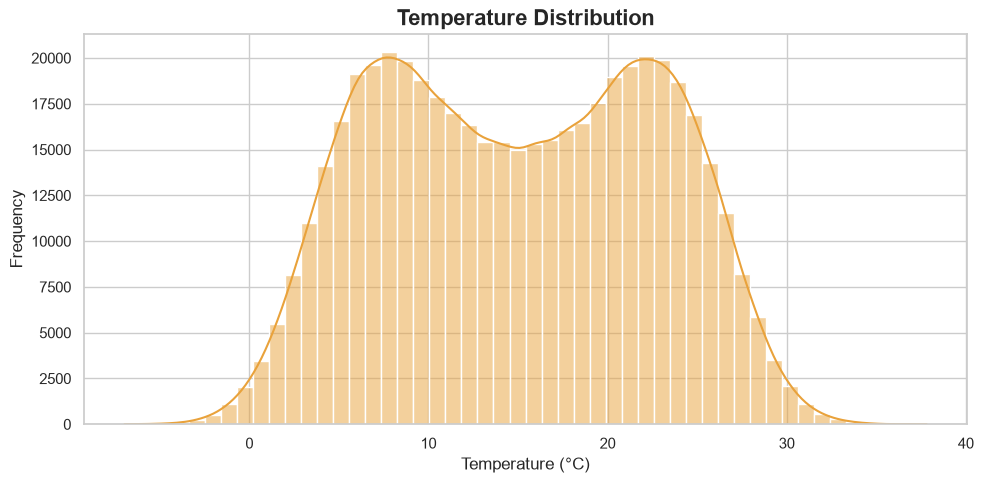

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="temperature_c",
    bins=50,
    kde=True,
    color="#E9A23B"
)

plt.title(
    "Temperature Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Temperature (°C)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

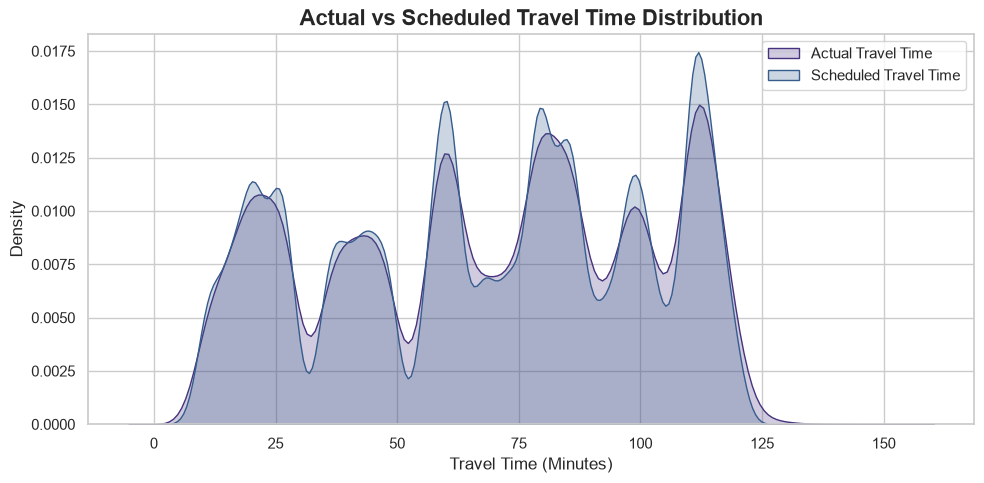

In [48]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=df,
    x="actual_travel_min",
    label="Actual Travel Time",
    fill=True,
    alpha=0.25
)

sns.kdeplot(
    data=df,
    x="scheduled_travel_min",
    label="Scheduled Travel Time",
    fill=True,
    alpha=0.25
)

plt.title(
    "Actual vs Scheduled Travel Time Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Travel Time (Minutes)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

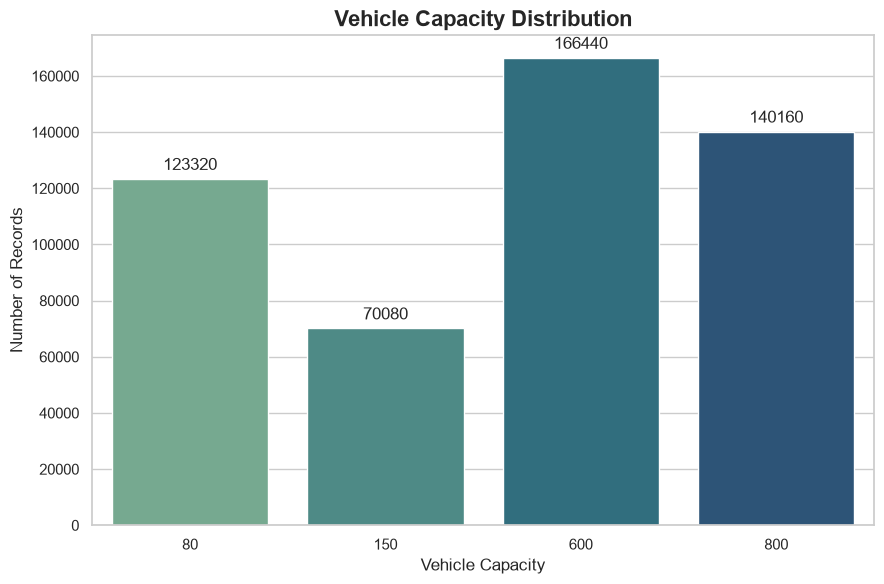

In [52]:
capacity_counts = df["vehicle_capacity"].value_counts().sort_index()

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=capacity_counts.index.astype(str),
    y=capacity_counts.values,
    hue=capacity_counts.index.astype(str),
    palette="crest",
    legend=False
)

plt.title(
    "Vehicle Capacity Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Vehicle Capacity", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

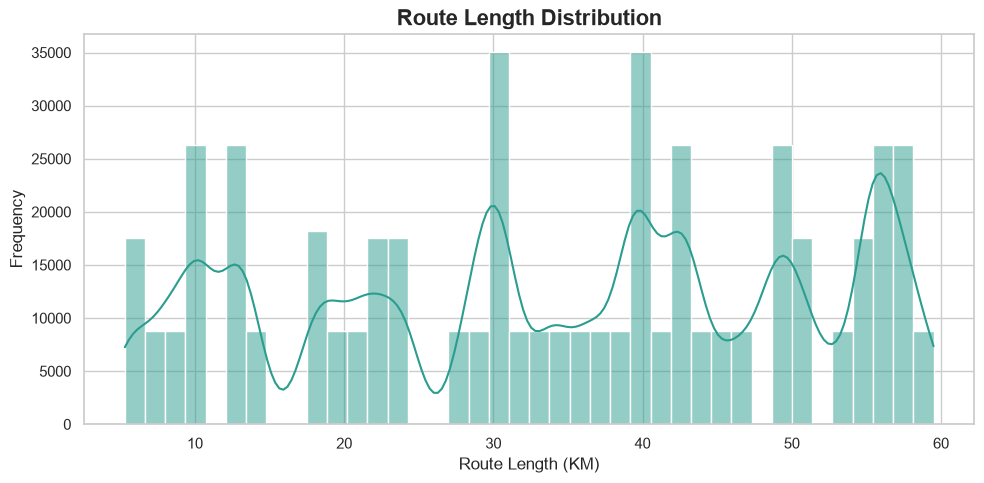

In [53]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="route_length_km",
    bins=40,
    kde=True,
    color="#2A9D8F"
)

plt.title(
    "Route Length Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Route Length (KM)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

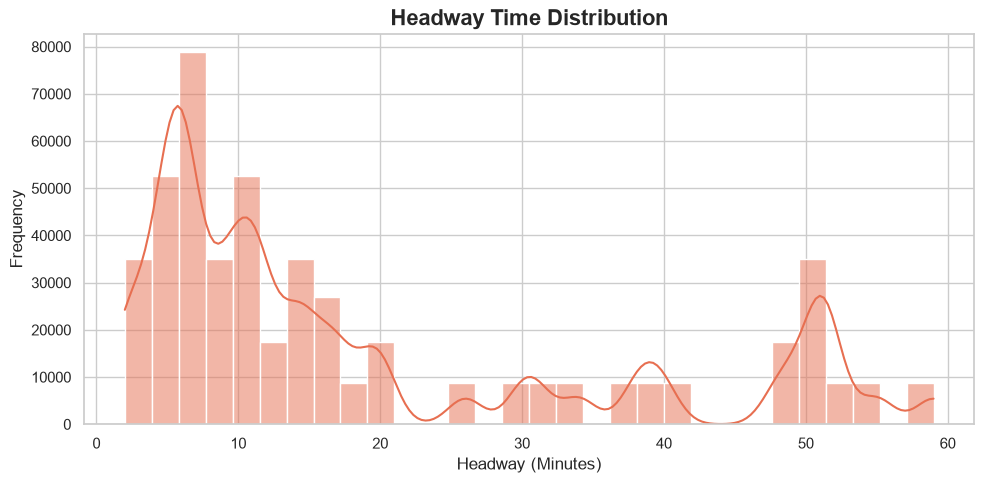

In [54]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="headway_min",
    bins=30,
    kde=True,
    color="#E76F51"
)

plt.title(
    "Headway Time Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Headway (Minutes)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

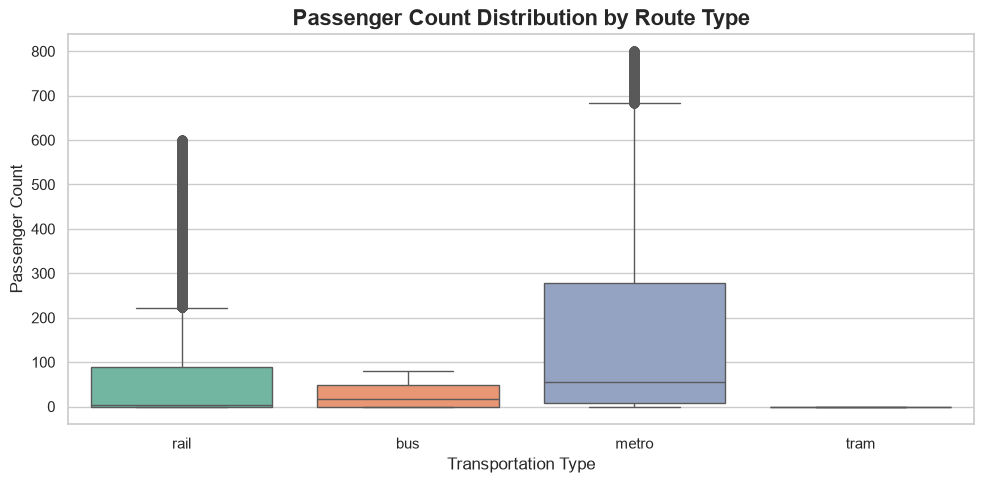

In [55]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="route_type",
    y="passenger_count",
    hue="route_type",
    palette="Set2",
    legend=False
)

plt.title(
    "Passenger Count Distribution by Route Type",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Transportation Type", fontsize=12)
plt.ylabel("Passenger Count", fontsize=12)

plt.tight_layout()
plt.show()

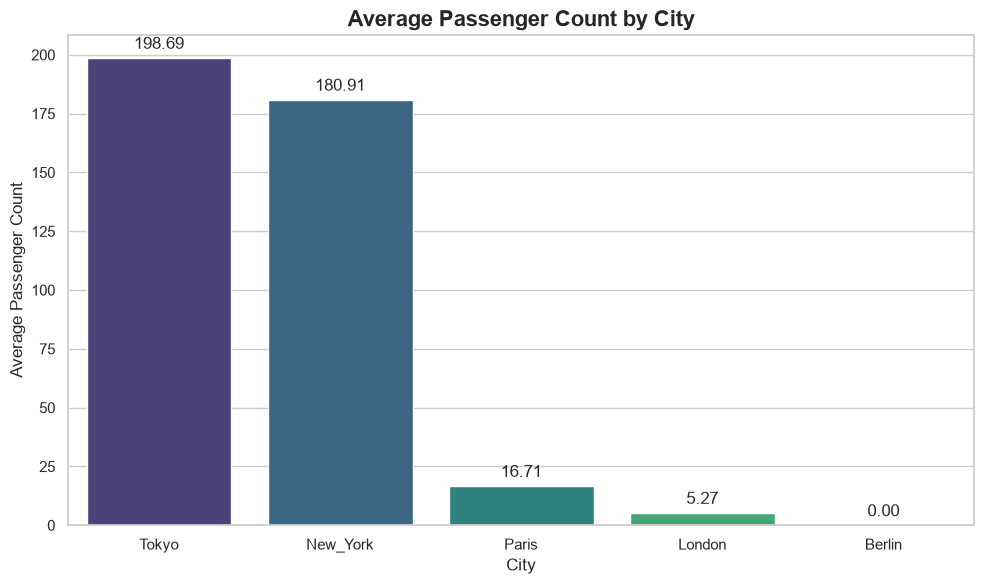

In [57]:
city_avg_passengers = (
    df.groupby("city")["passenger_count"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=city_avg_passengers.index,
    y=city_avg_passengers.values,
    hue=city_avg_passengers.index,
    palette="viridis",
    legend=False
)

plt.title(
    "Average Passenger Count by City",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("City", fontsize=12)
plt.ylabel("Average Passenger Count", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()
plt.show()

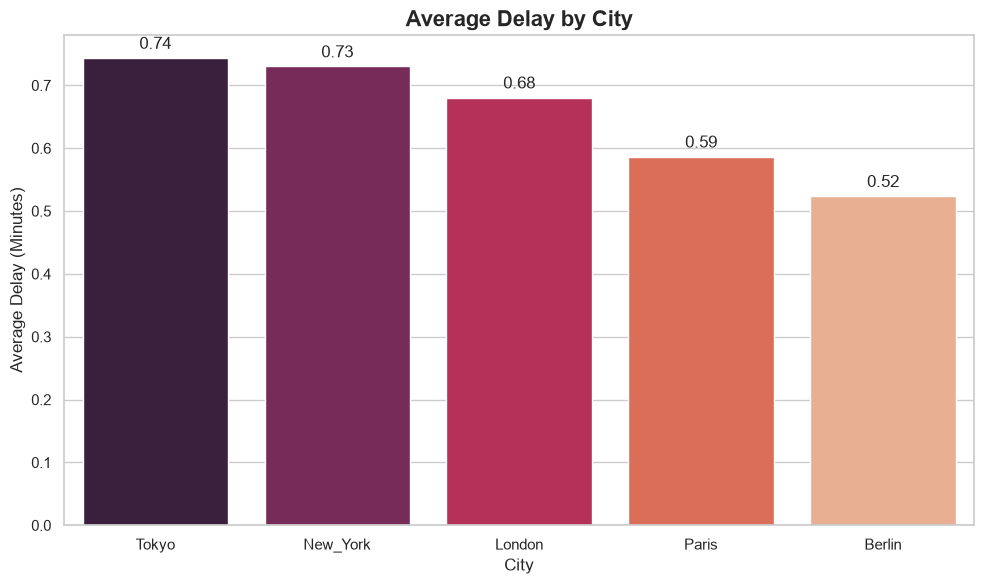

In [59]:
city_avg_delay = (
    df.groupby("city")["delay_minutes"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=city_avg_delay.index,
    y=city_avg_delay.values,
    hue=city_avg_delay.index,
    palette="rocket",
    legend=False
)

plt.title(
    "Average Delay by City",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("City", fontsize=12)
plt.ylabel("Average Delay (Minutes)", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()
plt.show()

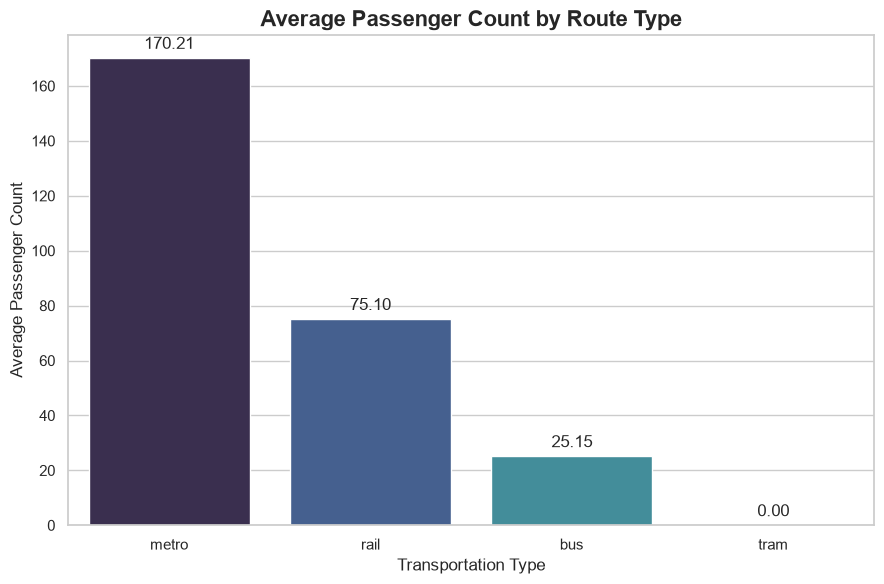

In [61]:
route_avg_passengers = (
    df.groupby("route_type")["passenger_count"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=route_avg_passengers.index,
    y=route_avg_passengers.values,
    hue=route_avg_passengers.index,
    palette="mako",
    legend=False
)

plt.title(
    "Average Passenger Count by Route Type",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Transportation Type", fontsize=12)
plt.ylabel("Average Passenger Count", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()
plt.show()

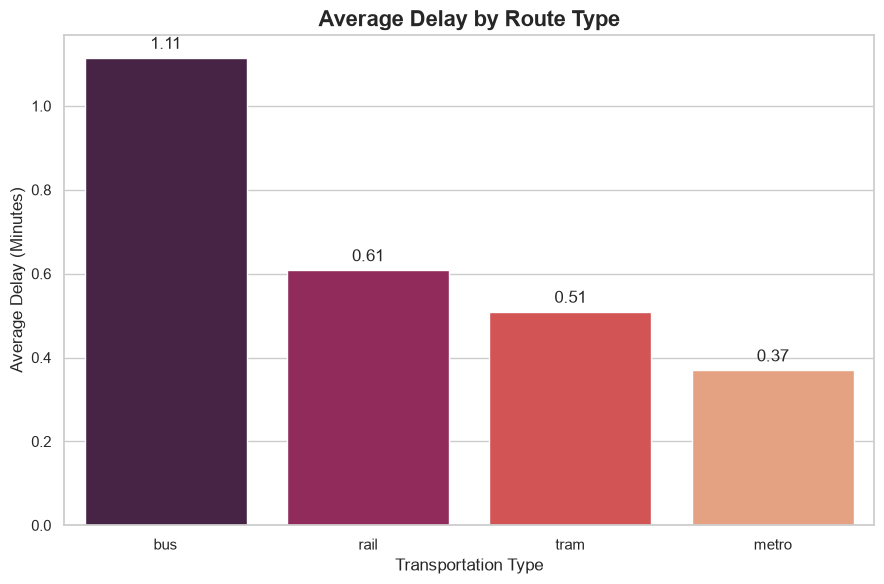

In [63]:
route_avg_delay = (
    df.groupby("route_type")["delay_minutes"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=route_avg_delay.index,
    y=route_avg_delay.values,
    hue=route_avg_delay.index,
    palette="rocket",
    legend=False
)

plt.title(
    "Average Delay by Route Type",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Transportation Type", fontsize=12)
plt.ylabel("Average Delay (Minutes)", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()
plt.show()

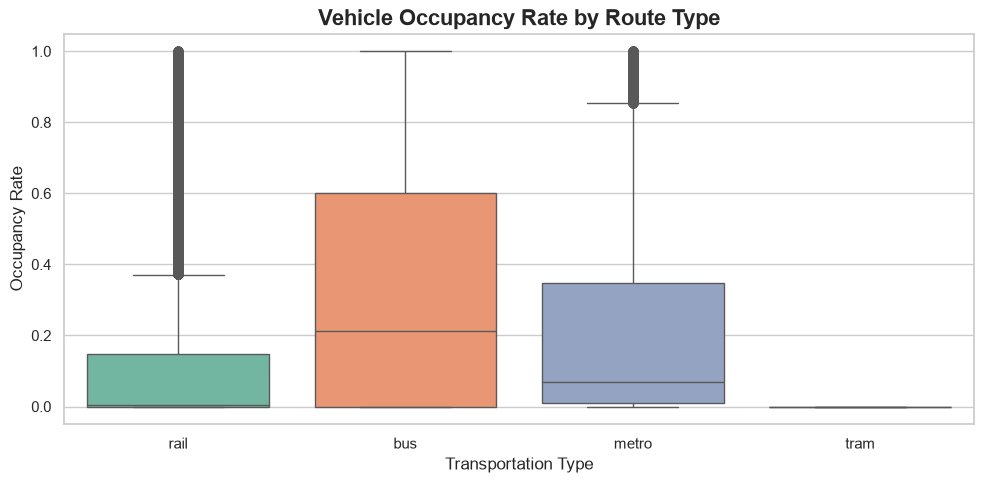

In [64]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="route_type",
    y="occupancy_rate",
    hue="route_type",
    palette="Set2",
    legend=False
)

plt.title(
    "Vehicle Occupancy Rate by Route Type",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Transportation Type", fontsize=12)
plt.ylabel("Occupancy Rate", fontsize=12)

plt.tight_layout()
plt.show()

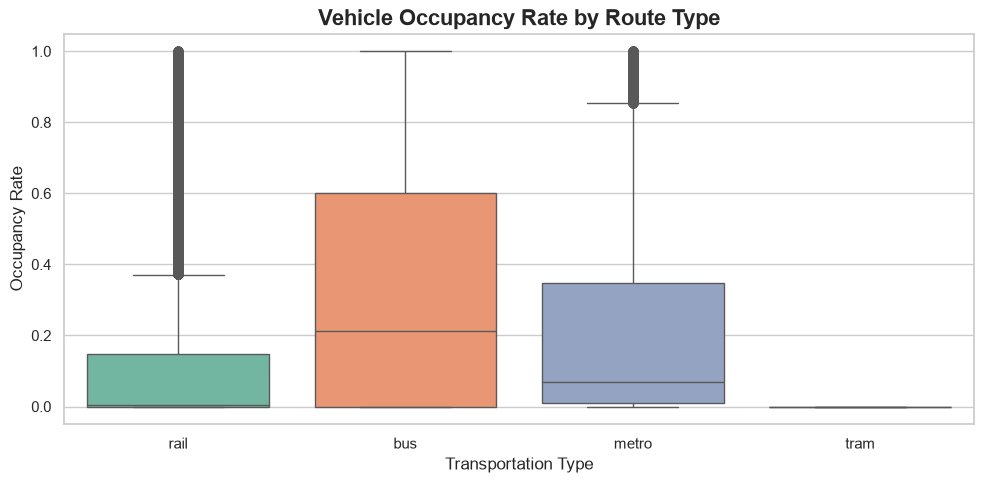

In [65]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df, x="route_type", y="occupancy_rate",
    hue="route_type", palette="Set2", legend=False
)

plt.title("Vehicle Occupancy Rate by Route Type",
          fontsize=16, fontweight="bold")
plt.xlabel("Transportation Type")
plt.ylabel("Occupancy Rate")
plt.tight_layout()
plt.show()

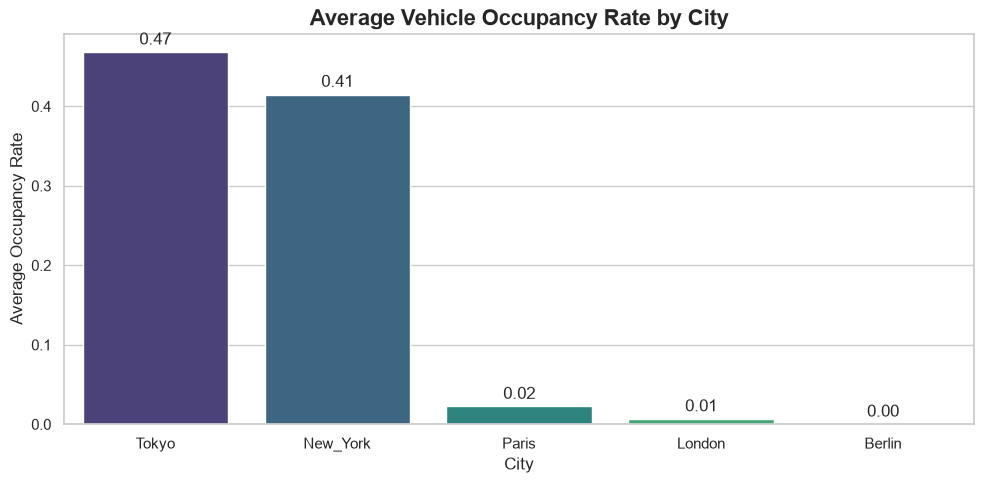

In [66]:
city_occupancy = (
    df.groupby("city")["occupancy_rate"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=city_occupancy.index,
    y=city_occupancy.values,
    hue=city_occupancy.index,
    palette="viridis",
    legend=False
)

plt.title("Average Vehicle Occupancy Rate by City",
          fontsize=16, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Average Occupancy Rate")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

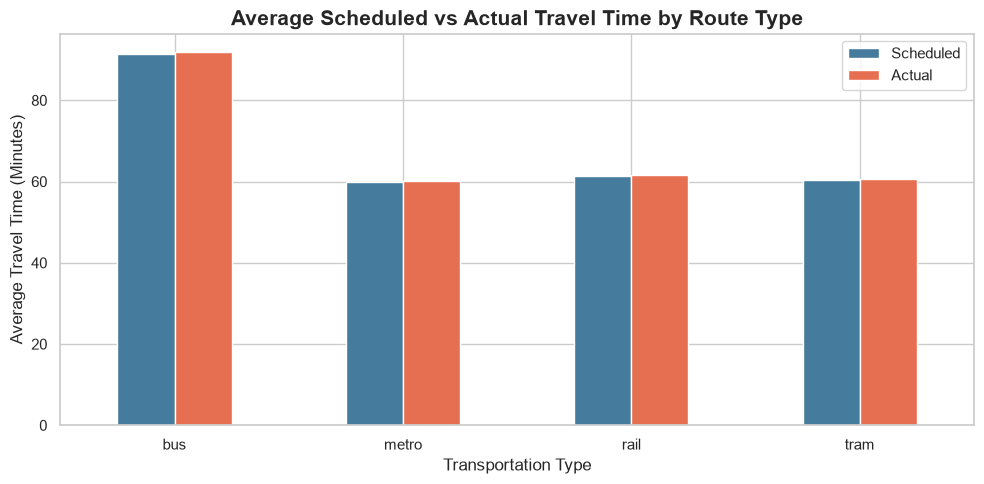

In [67]:
travel_time = df.groupby("route_type")[
    ["scheduled_travel_min", "actual_travel_min"]
].mean()

travel_time.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#457B9D", "#E76F51"]
)

plt.title("Average Scheduled vs Actual Travel Time by Route Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Transportation Type")
plt.ylabel("Average Travel Time (Minutes)")
plt.xticks(rotation=0)
plt.legend(["Scheduled", "Actual"])
plt.tight_layout()
plt.show()

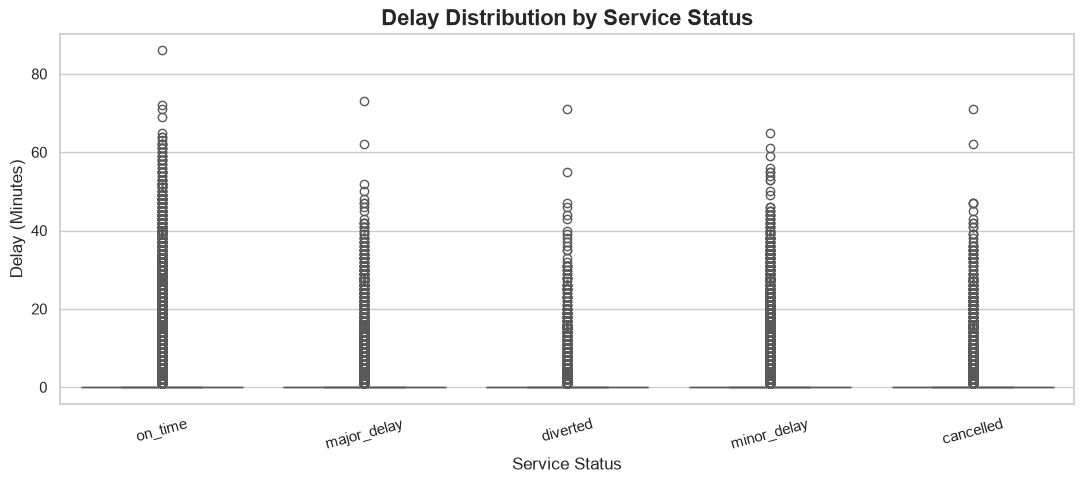

In [68]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df,
    x="service_status",
    y="delay_minutes",
    hue="service_status",
    palette="Set2",
    legend=False
)

plt.title("Delay Distribution by Service Status",
          fontsize=16, fontweight="bold")
plt.xlabel("Service Status")
plt.ylabel("Delay (Minutes)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

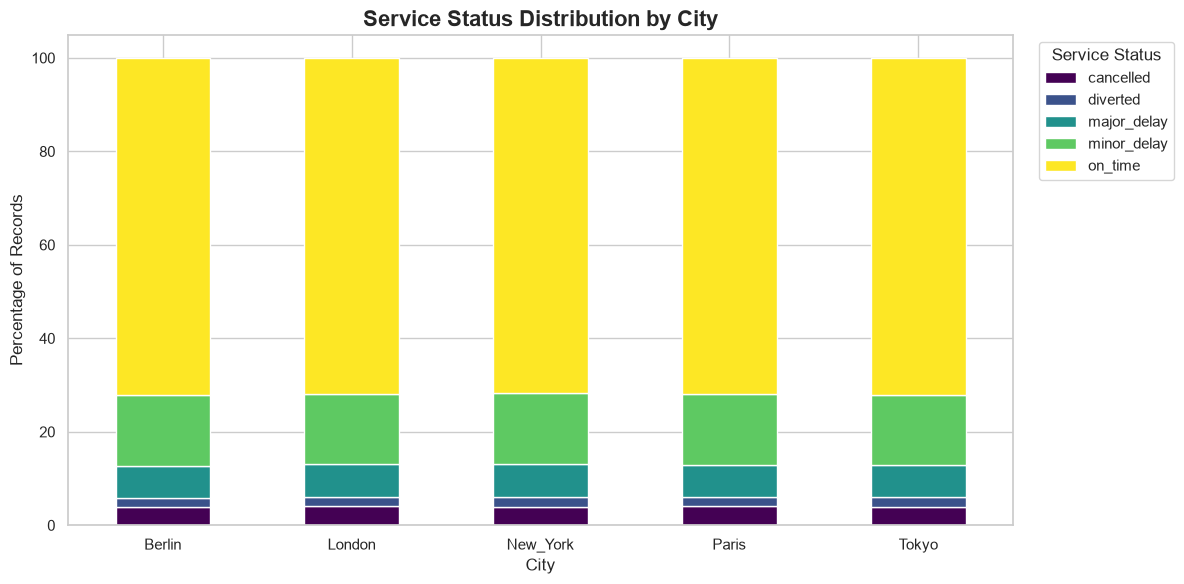

In [69]:
status_city = pd.crosstab(
    df["city"], df["service_status"], normalize="index"
) * 100

status_city.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="viridis"
)

plt.title("Service Status Distribution by City",
          fontsize=16, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Service Status", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

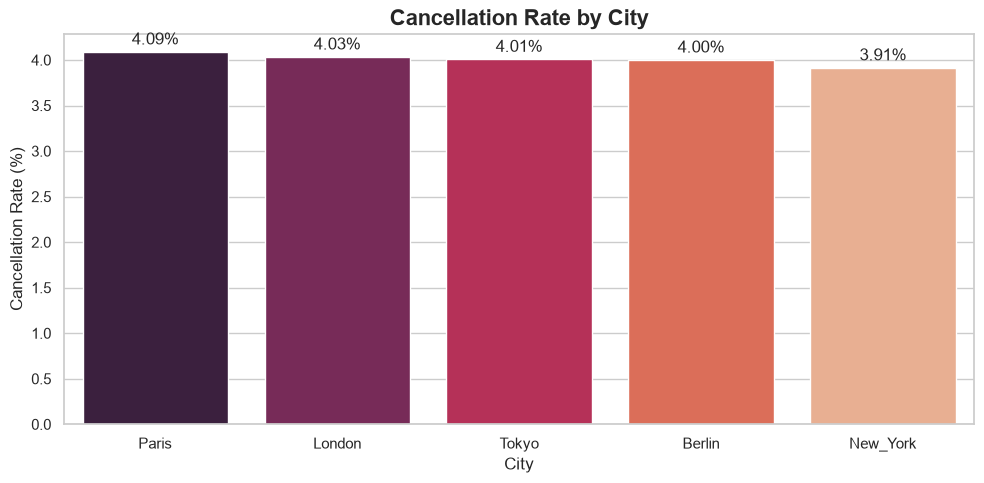

In [70]:
cancellation_rate = (
    df.groupby("city")["cancellation_flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=cancellation_rate.index,
    y=cancellation_rate.values,
    hue=cancellation_rate.index,
    palette="rocket",
    legend=False
)

plt.title("Cancellation Rate by City",
          fontsize=16, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Cancellation Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

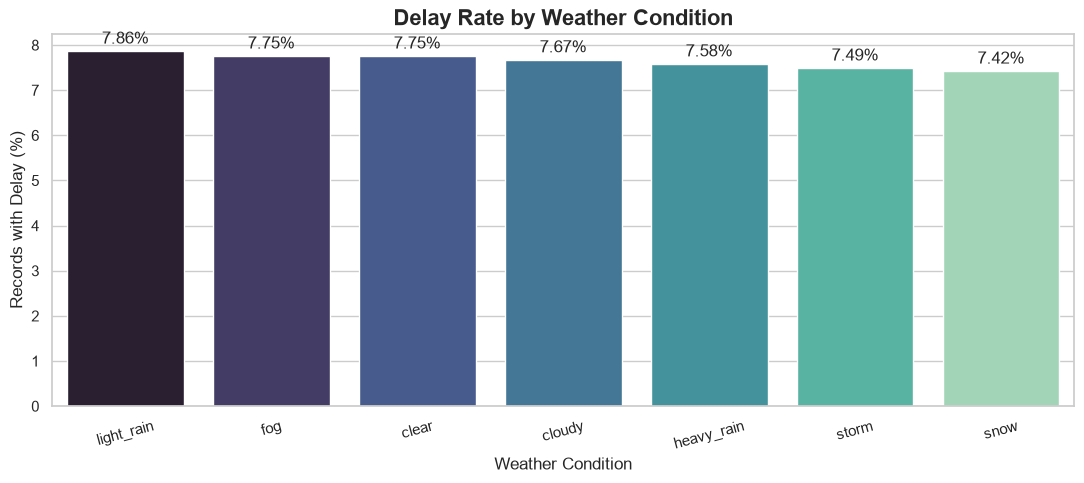

In [71]:
weather_delay = (
    df.assign(is_delayed=df["delay_minutes"] > 0)
    .groupby("weather_condition")["is_delayed"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    x=weather_delay.index,
    y=weather_delay.values,
    hue=weather_delay.index,
    palette="mako",
    legend=False
)

plt.title("Delay Rate by Weather Condition",
          fontsize=16, fontweight="bold")
plt.xlabel("Weather Condition")
plt.ylabel("Records with Delay (%)")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

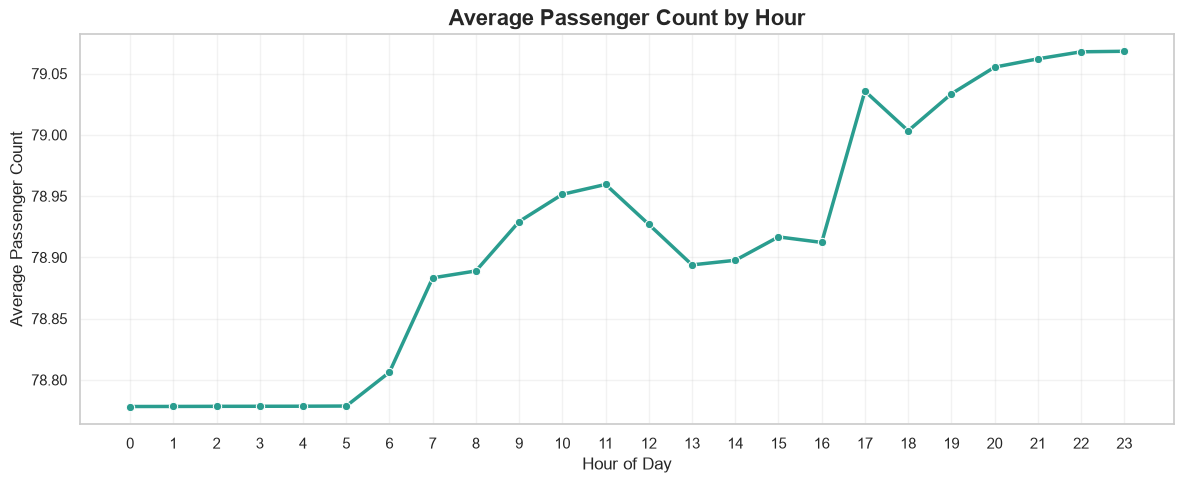

In [72]:
hourly_passengers = df.groupby("hour")["passenger_count"].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_passengers.index,
    y=hourly_passengers.values,
    marker="o",
    linewidth=2.5,
    color="#2A9D8F"
)

plt.title("Average Passenger Count by Hour",
          fontsize=16, fontweight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Average Passenger Count")
plt.xticks(range(0, 24))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

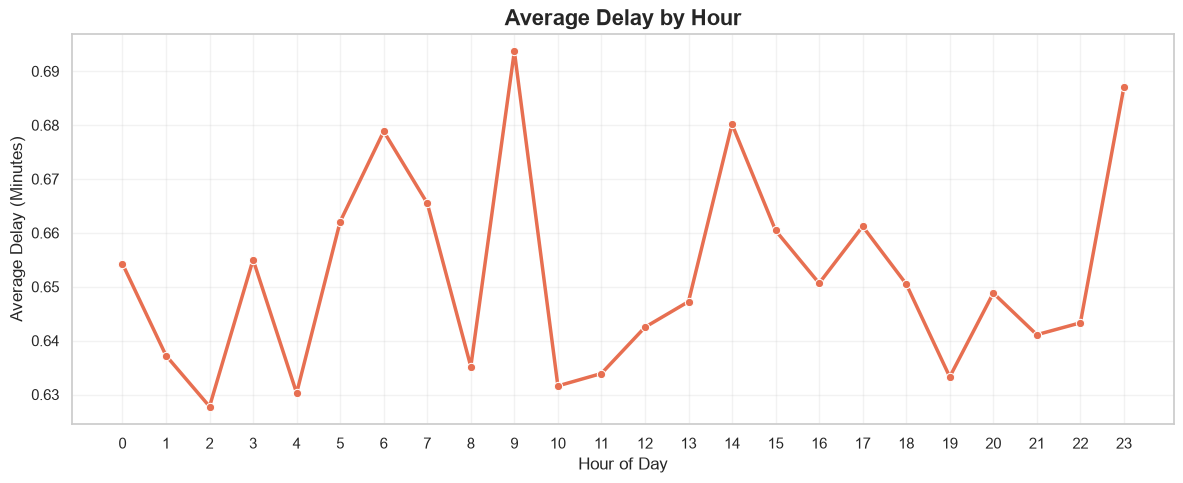

In [73]:
hourly_delay = df.groupby("hour")["delay_minutes"].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_delay.index,
    y=hourly_delay.values,
    marker="o",
    linewidth=2.5,
    color="#E76F51"
)

plt.title("Average Delay by Hour",
          fontsize=16, fontweight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

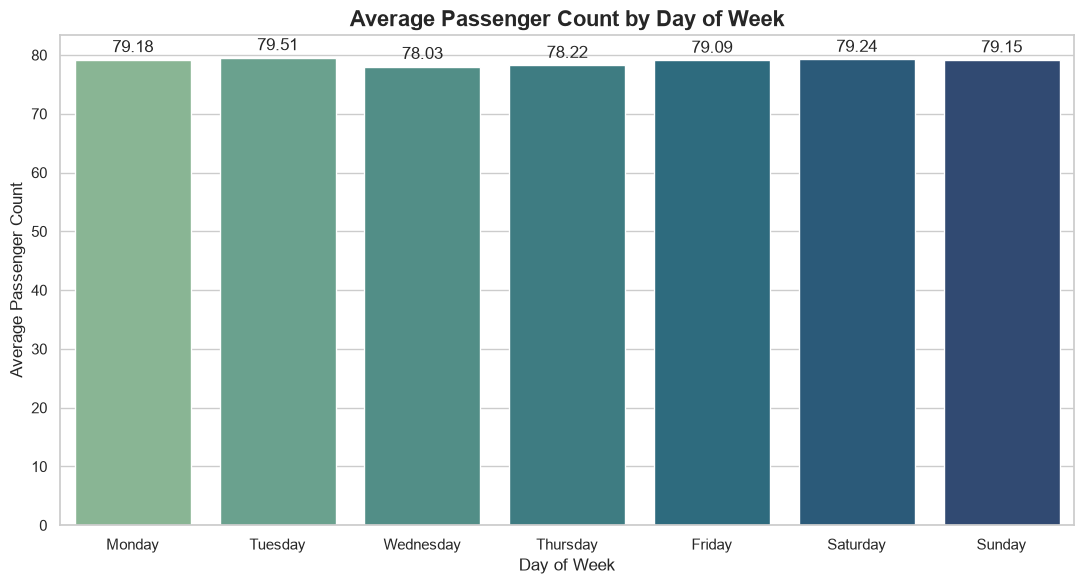

In [75]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_passengers = (
    df.groupby("day_name")["passenger_count"]
    .mean()
    .reindex(day_order)
)

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    x=day_passengers.index,
    y=day_passengers.values,
    hue=day_passengers.index,
    palette="crest",
    legend=False
)

plt.title("Average Passenger Count by Day of Week",
          fontsize=16, fontweight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Average Passenger Count")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

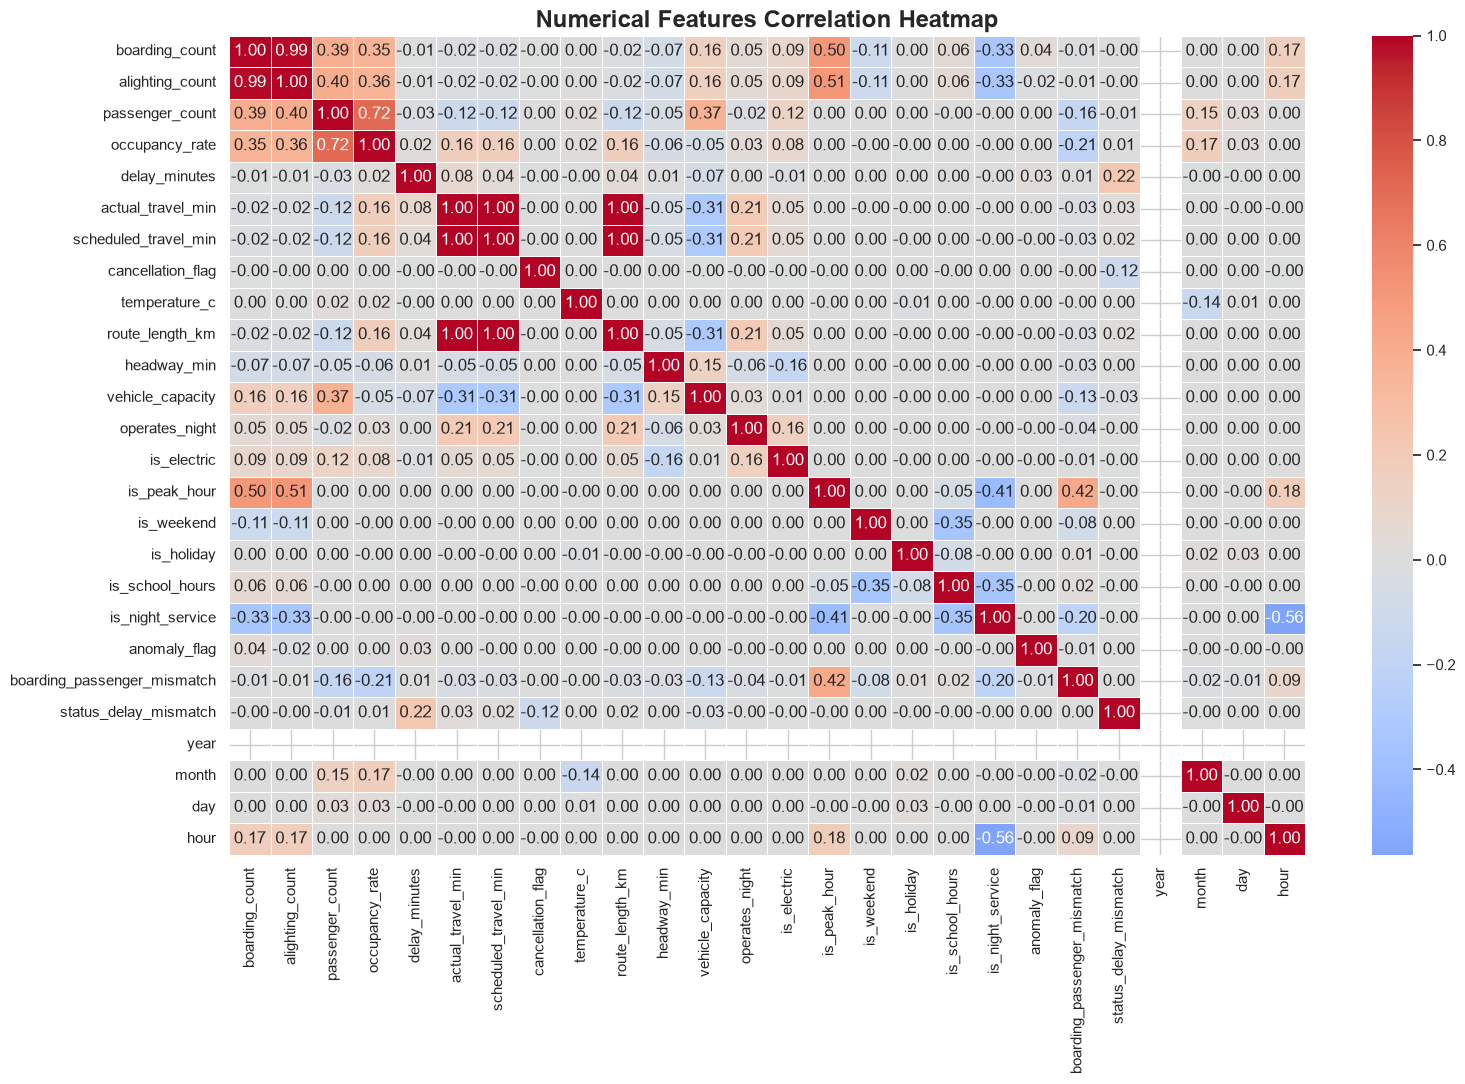

In [76]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(16, 11))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Features Correlation Heatmap",
          fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

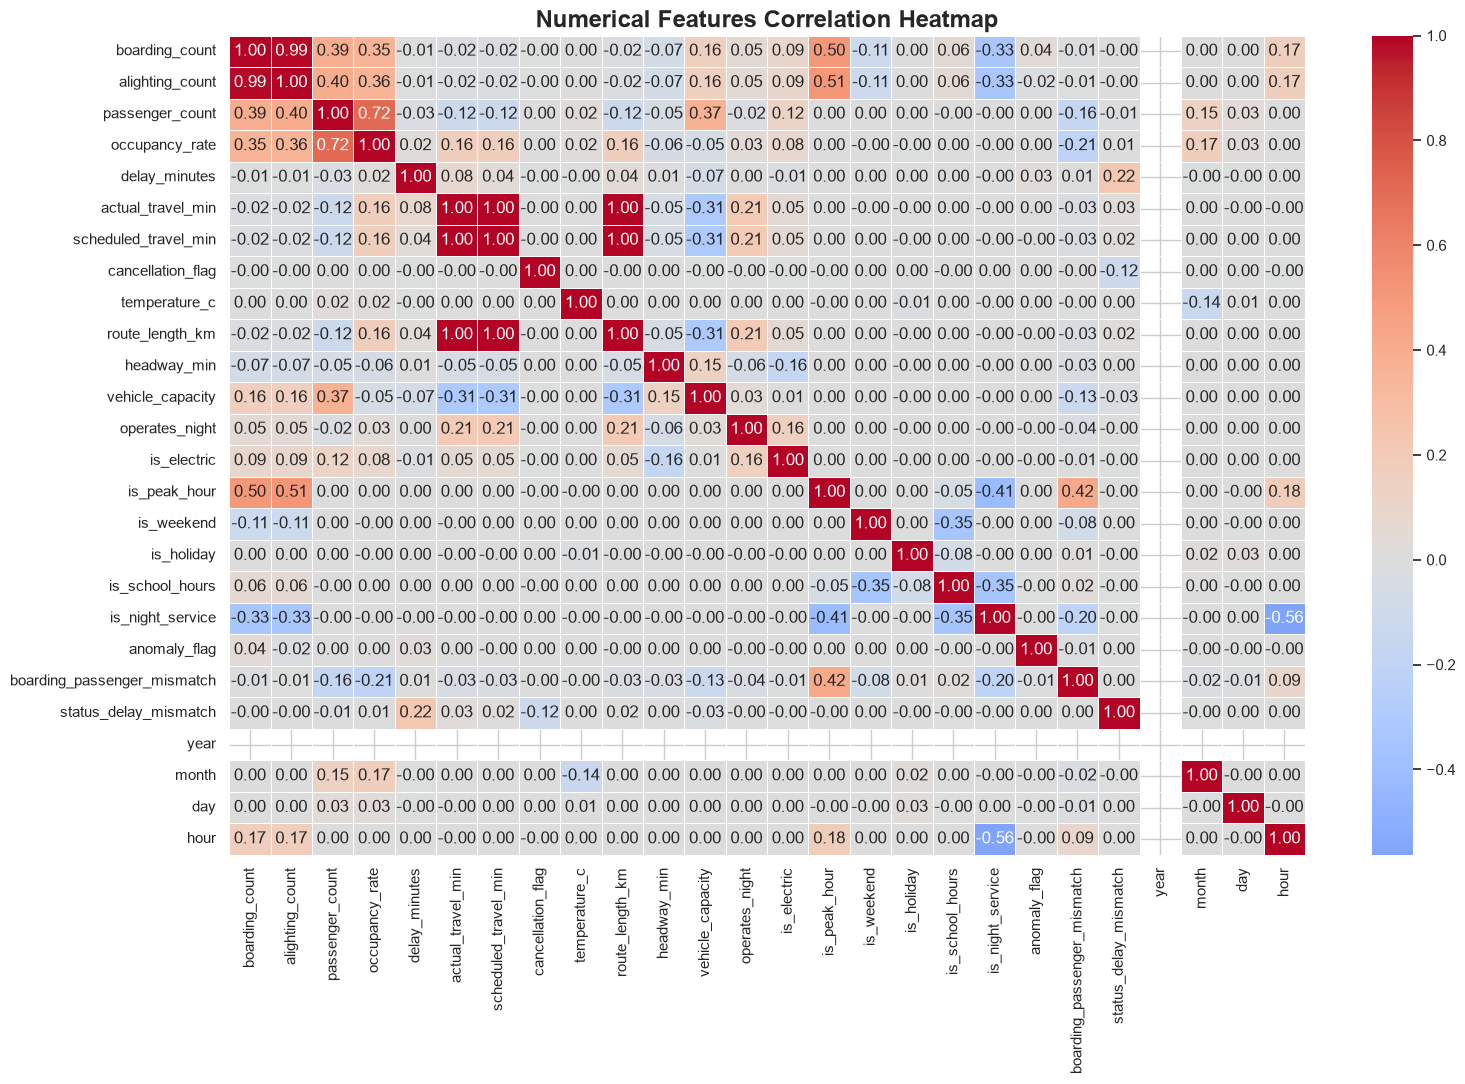

In [77]:
numeric_df = df.select_dtypes(include="number").drop(
    columns=["trip_id"], errors="ignore"
)

correlation = numeric_df.corr()

plt.figure(figsize=(16, 11))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Features Correlation Heatmap",
          fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

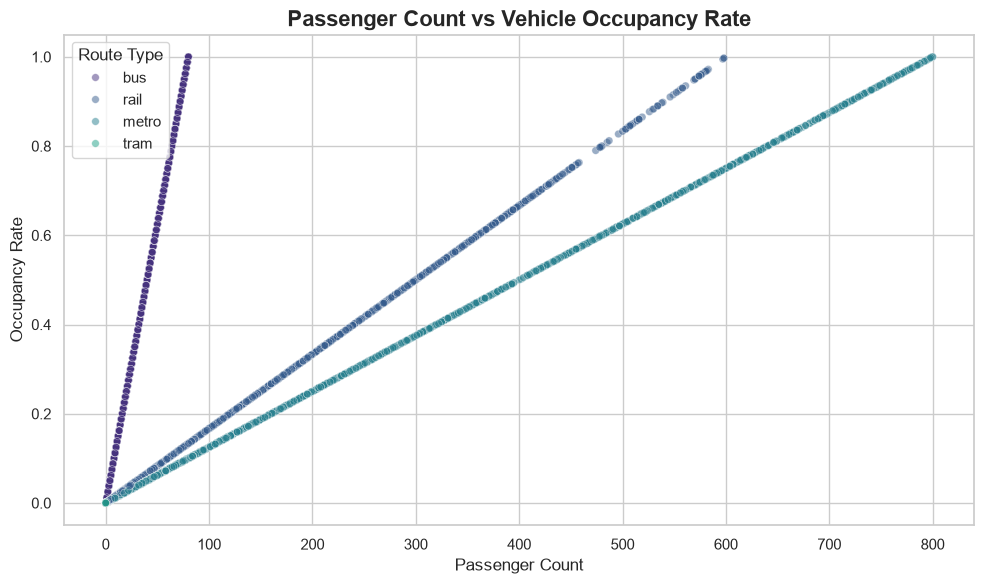

In [78]:
sample_df = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="passenger_count",
    y="occupancy_rate",
    hue="route_type",
    alpha=0.5,
    s=30
)

plt.title("Passenger Count vs Vehicle Occupancy Rate",
          fontsize=16, fontweight="bold")
plt.xlabel("Passenger Count")
plt.ylabel("Occupancy Rate")
plt.legend(title="Route Type")
plt.tight_layout()
plt.show()